In [46]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent))

import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

np.random.seed(2025)

from ipywidgets import interact, FloatSlider, IntSlider
import matplotlib.patches as patches

from src.tshred.models import TSHRED, fit
from src.shred.processdata import TimeSeriesDataset, Padding
from src.shred.utils import dim_reduction


## **Double gyre flow**

The double gyre flow is a time-dependent model for two counter-rotating vortices (gyres) in a rectangular domain. When time is introduced via a periodic perturbation, the central dividing line between the two gyres oscillates left and right, creating a time-varying velocity field that can lead to chaotic particle trajectories. The velocity field $\mathbf{v} = [u, v]^T$ in the domain $[0, L_x] \times [0, L_y]$ and in the time interval $[0, T]$ is given by

$$
\begin{align}
u(x, y, t) &= -\pi I \sin\left( \pi f(x, t) \right) \cos\left( \pi y \right)
\\
v(x, y, t) &= \pi I \cos\left( \pi f(x, t) \right) \sin\left( \pi y \right) \frac{\partial f}{\partial x}
\end{align}
$$

\
where $I$ is the intensity parameter, $f(x, t) = \epsilon \sin(\omega t) x^2 + (1 - 2\epsilon \sin(\omega t)) x $, $\epsilon$ and $\omega$ are the perturbation amplitude and the frequency of the oscillation, respectively.

## Solver

In [23]:
# DEFINE THE SYSTEM SOLVER

def double_gyre_flow(amplitude, frequency, x, y, t):
    '''
    Solve the double gyre flow problem

    Inputs
        amplitude                   (`float`)
        frequency                   (`float`)
        horizontal discretization   (`np.array[float]`, shape: (ny,))
        vertical discretization     (`np.array[float]`, shape: (nx,))
        time vector                 (`np.array[float]`, shape: (ntimes,))

    Output
        horizontal velocity matrix  (`np.array[float]`, shape: (ntimes, nx * ny)
        vertical velocity matrix    (`np.array[float]`, shape: (ntimes, nx * ny)
    '''

    xgrid, ygrid = np.meshgrid(x, y)         # spatial grid

    u = np.zeros((len(t), len(x), len(y)))   # horizontal velocity
    v = np.zeros((len(t), len(x), len(y)))   # vertical velocity

    intensity = 0.1   # intensity parameter

    f = lambda x,t: amplitude * np.sin(frequency * t) * x**2 + x - 2 * amplitude * np.sin(frequency * t) * x

    # compute solution
    for i in range(len(t)):
      u[i] = (-np.pi * intensity * np.sin(np.pi * f(xgrid, t[i])) * np.cos(np.pi * ygrid)).T
      v[i] = (np.pi * intensity * np.cos(np.pi * f(xgrid, t[i])) * np.sin(np.pi * ygrid) * (2 * amplitude * np.sin(frequency * t[i]) * xgrid + 1.0 - 2 * amplitude * np.sin(frequency * t[i]))).T

    return u, v

In [24]:
# DATA GENERATION

amplitude_range = np.array([0.0, 0.5])
frequency_range = np.array([0.5, 2*np.pi])

# spatial discretization
nx = 50
ny = 25
Lx = 2.0
Ly = 1.0
x = np.linspace(0, Lx, nx)
y = np.linspace(0, Ly, ny)
nstate = len(x) * len(y)

# temporal discretization
dt = 0.1
T = 10.0
t = np.arange(0, T + dt, dt)
ntimes = len(t)

# training data generation
ntrajectories = 100
U = np.zeros((ntrajectories, ntimes, nx, ny))
V = np.zeros((ntrajectories, ntimes, nx, ny))

for i in range(ntrajectories):
  amplitude = (amplitude_range[1] - amplitude_range[0]) * np.random.rand() + amplitude_range[0]
  frequency = (frequency_range[1] - frequency_range[0]) * np.random.rand() + frequency_range[0]
  U[i], V[i] = double_gyre_flow(amplitude, frequency, x, y, t)

# VORTICITY CALCULATION
def vorticity(u, v):
    dx = Lx / nx
    dy = Ly / ny
    du_dy = np.gradient(u, dy, axis = 1)
    dv_dx = np.gradient(v, dx, axis = 0)
    return dv_dx - du_dy

In [25]:
# DATA VISUALIZATION

def plot_data(which_trajectory, which_time):

    offset = 0.1

    plt.figure(figsize = (10,5))
    plt.contourf(x, y, vorticity(U[which_trajectory, which_time], V[which_trajectory, which_time]).T, cmap = 'seismic', levels = 100)
    plt.streamplot(x, y, U[which_trajectory, which_time].T, V[which_trajectory, which_time].T, color='black', linewidth = 1, density = 1)
    plt.axis('off')
    plt.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
    plt.title(f'Trajectory {which_trajectory} at time t = {round(t[which_time], 3)}')
    plt.grid(True)
    plt.gca().add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth = 5, edgecolor = 'black', facecolor = 'none'))

interact(
    plot_data, 
    which_trajectory = IntSlider(min = 0, max = ntrajectories - 1, step = 1, description='Trajectory'), 
    which_time = IntSlider(min = 0, max = ntimes - 1, step = 1, description='Time step')
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), IntSlider(value=0, description='Ti…

In [26]:
# TORCH CONVERSION

U = torch.from_numpy(U.reshape(ntrajectories, ntimes, nstate))
V = torch.from_numpy(V.reshape(ntrajectories, ntimes, nstate))

print(f'U shape: {U.shape} \nV shape: {V.shape}')

U shape: torch.Size([100, 101, 1250]) 
V shape: torch.Size([100, 101, 1250])


## Broken sensors simulations

In [27]:
# EXTRACT SENSORS DATA

nsensors = 3
short_broken = 1
long_broken = 1 

idx_sensors = np.random.choice(nstate, size = nsensors, replace = False)
idx_short_broken_s = idx_sensors[0:short_broken]
idx_long_broken_s = idx_sensors[short_broken:short_broken+long_broken]

print("Available sensors:\t", idx_sensors)
print("short broken sensors:\t", idx_short_broken_s)
print("long broken sensors:\t", idx_long_broken_s)

sensors_data = U[:,:,idx_sensors]

idx_sensors_x, idx_sensors_y = np.unravel_index(idx_sensors, (nx, ny))
sensors_coordinates = np.vstack((x[idx_sensors_x], y[idx_sensors_y]))

Available sensors:	 [690 587 929]
short broken sensors:	 [690]
long broken sensors:	 [587]


In [28]:
# SHORT BROKEN SIMULATION

# broken = bernoulli distribution
p_short_broken = 0.2
for idx in idx_short_broken_s:
    local_idx = np.where(idx_sensors == idx)[0][0]

    mask_train = torch.rand(sensors_data[:, :, local_idx].shape) < p_short_broken
    print("simulation of short broken sensor idx\t", idx, "\twith probability", p_short_broken)

    sensors_data[:, :, local_idx][mask_train] = float('nan')


# LONG BROKEN SIMULATION

#draw 2 numbers and erase in the middle
for idx in idx_long_broken_s:
    local_idx = np.where(idx_sensors == idx)[0][0]

    t1, t2 = np.random.randint(0, ntimes, size=2)
    t_start, t_end = min(t1, t2), max(t1, t2)
    if t_end - t_start < 30: # if the interval is too short, make it longer
        t_end = min(t_start + 38, ntimes-1)
    print("simulation of long broken sensor idx\t", idx, "\tfrom time step", t_start, "to time step", t_end)

    sensors_data[:, t_start:t_end + 1, local_idx] = float('nan')

simulation of short broken sensor idx	 690 	with probability 0.2
simulation of long broken sensor idx	 587 	from time step 42 to time step 80


In [29]:
# PLOT DATA AVAILABILITY

def plot_data_availability(sensor_data, title_prefix, trajectory=0, sensor_labels=None):
    traj_idx = min(trajectory, sensor_data.shape[0] - 1)
    availability = (~torch.isnan(sensor_data[traj_idx])).to(torch.float32).cpu().numpy()
    time = np.arange(availability.shape[0])
    nsensors_plot = availability.shape[1]

    if sensor_labels is None:
        sensor_labels = np.arange(nsensors_plot)
    sensor_labels = np.asarray(sensor_labels)

    if sensor_labels.shape[0] != nsensors_plot:
        raise ValueError("sensor_labels length must match number of sensor columns")

    fig_height = max(3.0, 0.7 * nsensors_plot)
    _, ax = plt.subplots(1, 1, figsize=(14, fig_height))

    for sensor_idx in range(nsensors_plot):
        line = np.where(availability[:, sensor_idx] > 0.5, sensor_idx + 1.0, np.nan)
        ax.plot(time, line, linewidth=4, solid_capstyle="butt", label=f"S{sensor_labels[sensor_idx]}")

    ax.set_xlabel("Time step")
    ax.set_ylabel("Sensor")
    ax.set_yticks(np.arange(1, nsensors_plot + 1))
    ax.set_yticklabels([f"S{label}" for label in sensor_labels])
    ax.set_ylim(0.5, nsensors_plot + 0.5)
    ax.grid(True, axis="x", alpha=0.25)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Sensors")

    plt.title(f"{title_prefix} - Trajectory {traj_idx}")
    plt.tight_layout()
    plt.show()

In [30]:
def plot_train_data_availability(trajectory=0):
    plot_data_availability(
        sensors_data,
        "Train availability",
        trajectory,
        sensor_labels=np.arange(sensors_data.shape[2])
    )

interact(
    plot_train_data_availability,
    trajectory=IntSlider(min=0, max=sensors_data.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), Output()), _dom_classes=('widget-i…

In [31]:
print("U shape: \t", U.shape)
print("V shape: \t", V.shape)
print("input shape: \t", sensors_data.shape)

U shape: 	 torch.Size([100, 101, 1250])
V shape: 	 torch.Size([100, 101, 1250])
input shape: 	 torch.Size([100, 101, 3])


## TRAIN VAL TEST split

In [32]:
## Splitting the data into train, valid and test sets

#split the sizes
train_size = int(0.8 * ntrajectories)
val_size = int(0.1 * ntrajectories)
test_size = ntrajectories - train_size - val_size
print(f"Train size: {train_size} \nValidation size: {val_size} \nTest size: {test_size}")

#shuffle the data
shuffle_indices = torch.randperm(ntrajectories)
U = U[shuffle_indices]
V = V[shuffle_indices]
sensors_data = sensors_data[shuffle_indices]

#split the data
U_train, U_val, U_test = torch.split(U, [train_size, val_size, test_size], dim=0)
V_train, V_val, V_test = torch.split(V, [train_size, val_size, test_size], dim=0)
input_train, input_val, input_test = torch.split(sensors_data, [train_size, val_size, test_size], dim=0)

#print 
print(f"\nU_train shape:\t{U_train.shape} \nV_train shape:\t{V_train.shape} \ninput_train shape:\t{input_train.shape}")
print(f"\nU_val shape:\t{U_val.shape} \nV_val shape:\t{V_val.shape} \ninput_val shape:\t{input_val.shape}")
print(f"\nU_test shape:\t{U_test.shape} \nV_test shape:\t{V_test.shape} \ninput_test shape:\t{input_test.shape}")


Train size: 80 
Validation size: 10 
Test size: 10

U_train shape:	torch.Size([80, 101, 1250]) 
V_train shape:	torch.Size([80, 101, 1250]) 
input_train shape:	torch.Size([80, 101, 3])

U_val shape:	torch.Size([10, 101, 1250]) 
V_val shape:	torch.Size([10, 101, 1250]) 
input_val shape:	torch.Size([10, 101, 3])

U_test shape:	torch.Size([10, 101, 1250]) 
V_test shape:	torch.Size([10, 101, 1250]) 
input_test shape:	torch.Size([10, 101, 3])


## POD based reduction

Residual energy is equal to  6.895568671295645e-07



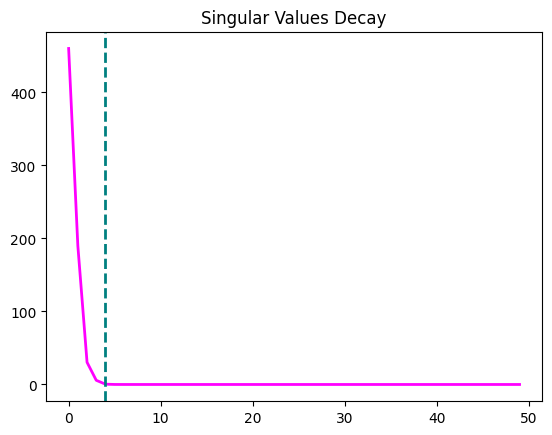

Residual energy is equal to  5.858244337896561e-06



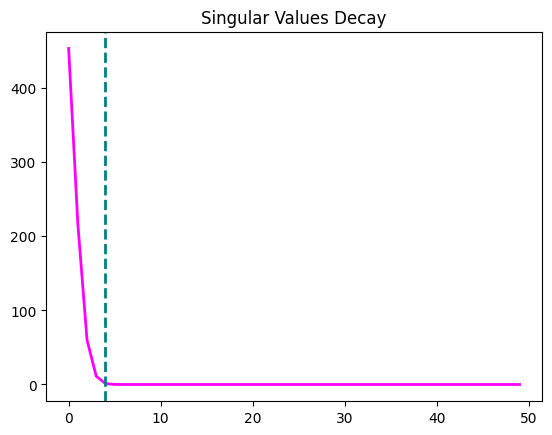

In [33]:
POD_modes = 4

## Dimensionality reduction with POD

U_train, U_val, U_test, U_train_proj, U_val_proj, U_test_proj, V1_POD = dim_reduction(U_train, U_val, U_test, POD_modes)
V_train, V_val, V_test, V_train_proj, V_val_proj, V_test_proj, V2_POD = dim_reduction(V_train, V_val, V_test, POD_modes)

In [34]:
print(f'U_train shape:\t\t{U_train.shape}')
print(f'U_train_proj shape:\t{U_train_proj.shape}')
print(f'V_train shape:\t\t{V_train.shape}')
print(f'V_train_proj shape:\t{V_train_proj.shape}')

U_train shape:		torch.Size([80, 101, 1250])
U_train_proj shape:	torch.Size([80, 101, 4])
V_train shape:		torch.Size([80, 101, 1250])
V_train_proj shape:	torch.Size([80, 101, 4])


In [35]:
ERRORS = []

## **Idea 0: Only Availabe Sensors**

In [36]:
interact(
    plot_train_data_availability,
    trajectory=IntSlider(min=0, max=sensors_data.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), Output()), _dom_classes=('widget-i…

In [37]:
## REMOVE SENSORS NOT ALWAYS AVAILABLE

# Keep only sensors that are always available in all splits.
always_available_mask = (
    ~torch.isnan(input_train).any(dim=(0, 1)) & 
    ~torch.isnan(input_val).any(dim=(0, 1)) & 
    ~torch.isnan(input_test).any(dim=(0, 1))
)

# Get indices of sensors to keep and remove
keep_sensor_idx = np.where(always_available_mask.cpu().numpy())[0]
removed_sensor_idx = np.setdiff1d(np.arange(nsensors), keep_sensor_idx)
navailable_sensors = len(keep_sensor_idx)

# Clean the input data by keeping only the always available sensors
cleaned_input_train = input_train[:, :, keep_sensor_idx]
cleaned_input_val = input_val[:, :, keep_sensor_idx]
cleaned_input_test = input_test[:, :, keep_sensor_idx]

print("Kept local sensor columns:\t", keep_sensor_idx)
print("Removed local sensor columns:\t", removed_sensor_idx)
print("Number of available sensors after cleaning:\t", navailable_sensors)

# PLOT CLEANED DATA AVAILABILITY (TRAIN ONLY)
def plot_cleaned_train_data_availability(trajectory=0):
    plot_data_availability(
        cleaned_input_train,
        "Cleaned Train availability",
        trajectory,
        sensor_labels=keep_sensor_idx
    )

interact(
    plot_cleaned_train_data_availability,
    trajectory=IntSlider(min=0, max=cleaned_input_train.shape[0] - 1, step=1, value=0, description="Trajectory"),
);


Kept local sensor columns:	 [2]
Removed local sensor columns:	 [0 1]
Number of available sensors after cleaning:	 1


interactive(children=(IntSlider(value=0, description='Trajectory', max=79), Output()), _dom_classes=('widget-i…

In [38]:
# BUILD TRAIN, VALIDATION AND TEST DATASETS WITH PADDING

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

lag = 25

train_data_in = Padding(cleaned_input_train, lag).to(device)
valid_data_in = Padding(cleaned_input_val, lag).to(device)
test_data_in = Padding(cleaned_input_test, lag).to(device)

train_data_out = Padding(torch.cat((U_train_proj, V_train_proj), 2), 1).squeeze(1).to(device)
valid_data_out = Padding(torch.cat((U_val_proj, V_val_proj), 2), 1).squeeze(1).to(device)
test_data_out = Padding(torch.cat((U_test_proj, V_test_proj), 2), 1).squeeze(1).to(device)

train_dataset = TimeSeriesDataset(train_data_in, train_data_out)
valid_dataset = TimeSeriesDataset(valid_data_in, valid_data_out)
test_dataset = TimeSeriesDataset(test_data_in, test_data_out)

print(f"Train dataset shape: \n{train_data_in.shape} -> {train_data_out.shape}")
print(f"Validation dataset shape: \n{valid_data_in.shape} -> {valid_data_out.shape}")
print(f"Test dataset shape: \n{test_data_in.shape} -> {test_data_out.shape}")


Using device: cpu
Train dataset shape: 
torch.Size([8080, 25, 1]) -> torch.Size([8080, 8])
Validation dataset shape: 
torch.Size([1010, 25, 1]) -> torch.Size([1010, 8])
Test dataset shape: 
torch.Size([1010, 25, 1]) -> torch.Size([1010, 8])


In [61]:
model_args = dict(
    # Encoder
    encoder         = "vanilla_transformer",
    encoder_depth   = 1,
    d_model         = navailable_sensors,   # input feature dim (one value per sensor)
    n_heads         = 4,
    dim_feedforward = 64,
    hidden_size     = 20,                   # must be divisible by n_heads (20 / 4 = 5 ✓)
    input_length    = lag,

    # Decoder
    decoder         = "cnn",
    decoder_depth   = 1,
    output_size     = 2 * POD_modes,        # U + V POD coefficients

    # Shared
    dropout         = 0.0,
    device          = device,
)
tshred = TSHRED(args=model_args)

In [62]:
train_errors, valid_errors = fit(
    tshred, train_dataset, valid_dataset, 
    batch_size = 64, epochs = 200, lr = 1e-3, verbose = True, patience = 40
)


Training:   0%|          | 0/200 [00:00<?, ?it/s]


TypeError: unsupported operand type(s) for -: 'Tensor' and 'dict'